In [1]:
#import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
import xgboost as xgb
from catboost import CatBoostRegressor, Pool
import shap

In [2]:
#import the data downloaded from the questionaire
data = pd.read_excel("Investigation into the usability of Games Console’s dashboards_in-game  menu screens(1-78).xlsx")

#remove redundant/useless columns
data.drop(['ID','Start time', 'Completion time', 'Email', 'Name', 'Last modified time', 'Please tick box if you agree with the statement:'], axis=1, inplace=True)
data

,Please indicate your Age,Please indicate your Sex (as entered at birth),Please select your preferred family of Game Console,Please select your favourite Genre,Games in Your Favourite Genre,Other Games,"Please list up to 3 of your favourite games from your favourite genre (separated with a "","")",Racing Games,Other Games2,Choose your favourite games from the Racing genre,...,How easy is it to adjust accessibility options?,How easy is it to recover from errors made when navigating menus?,How easy is it to recover from errors when changing options?,How quick is it to navigate the menus?,How quick do the menus' controls respond?,How quick is it to start a new game/load a save file?,How consistent is the menu design across the game?,How consistent is the position of the menu?,How consistent is the menu design with the theming of the game?,Please rate the general ease of use of the menus
0,36-45,Male,Playstation,Racing,NaN,NaN,NaN,Significantly Experienced,Significantly Experienced,Gran Turismo;Mario Kart;,...,Neither Hard nor Easy,Neither Hard nor Easy,Neither Hard nor Easy,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4
1,18-25,Male,Nintendo,Racing,NaN,NaN,NaN,Significantly Experienced,Significantly Experienced,Mario Kart;Sonic Racing;Kirby Air Riders;,...,Neither Hard nor Easy,Easy,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4
2,18-25,Male,Nintendo,2D Platformer,NaN,NaN,NaN,NaN,NaN,NaN,...,Neither Hard nor Easy,Easy,Easy,Very Quick,Quick,Very Quick,Often Consistent,Often Consistent,Always Consistent,4
3,18-25,Male,Nintendo,RPG,NaN,NaN,NaN,NaN,NaN,NaN,...,Easy,Easy,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,5
4,18-25,Male,PC,Racing,NaN,NaN,NaN,Extremely Experienced,Significantly Experienced,BeamNG.Drive;,...,Easy,Easy,Easy,Very Quick,Very Quick,Acceptable,Often Consistent,Sometimes Consistent,Sometimes Consistent,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,18-25,Male,Nintendo,RPG,NaN,NaN,NaN,NaN,NaN,NaN,...,Very Easy,Very Easy,Very Easy,Very Quick,Quick,Very Quick,Always Consistent,Often Consistent,Always Consistent,4
74,46-55,Male,Playstation,Survival Horror,NaN,NaN,NaN,NaN,NaN,NaN,...,Very Easy,Very Easy,Very Easy,Quick,Very Quick,Quick,Often Consistent,Often Consistent,Sometimes Consistent,4
75,46-55,Female,Playstation,Survival Horror,NaN,NaN,NaN,NaN,NaN,NaN,...,Easy,Neither Hard nor Easy,Easy,Quick,Quick,Very Quick,Always Consistent,Always Consistent,Never Consistent,3
76,18-25,Male,Playstation,Survival Horror,NaN,NaN,NaN,NaN,NaN,NaN,...,Very Easy,Easy,Very Easy,Quick,Very Quick,Quick,Always Consistent,Always Consistent,Sometimes Consistent,4


In [3]:
#rename columns to more readable names
data['Age']=data['Please indicate your Age']
data['Sex']=data['Please indicate your Sex (as entered at birth)']
data['Console']=data['Please select your preferred family of Game Console']
data['Genre']=data['Please select your favourite Genre ']
data['Options']=data['How easy is it to find the options you are after?']
data['Options Feedback']=data['How easy is it to interpret the feedback when selecting an option?']
data['Joystick']=data['How easy is it to navigate the menus with a joystick?']
data['DPad']=data['How easy is it to navigate the menus with a directional pad?']
data['Background']=data['How easy is it to differentiate the menus from the background?']
data['Font']=data['How easy is the font to read?']
data['Distinguish']=data['How easy is it to distinguish between the different options available?']
data['Settings']=data['How easy is it to adjust settings?']
data['Accessibility']=data['How easy is it to find accessibility options?']
data['Adjust Accessibility']=data['How easy is it to adjust accessibility options?']
data['Recover Nav']=data['How easy is it to recover from errors made when navigating menus?']
data['Recover Options']=data['How easy is it to recover from errors when changing options?']
data['Quick Nav']=data['How quick is it to navigate the menus?']
data['Quick Controls']=data["How quick do the menus' controls respond?"]
data['Load/Start']=data['How quick is it to start a new game/load a save file?']
data['Design Consistency']=data['How consistent is the menu design across the game?']
data['Position Consistency']=data['How consistent is the position of the menu?']
data['Theming']=data['How consistent is the menu design with the theming of the game?']
data['Rating']=data['Please rate the general ease of use of the menus']
data.drop(['Please indicate your Age','Please indicate your Sex (as entered at birth)','Please select your preferred family of Game Console','Please select your favourite Genre ','How easy is it to find the options you are after?','How easy is it to interpret the feedback when selecting an option?','How easy is it to navigate the menus with a joystick?','How easy is it to navigate the menus with a directional pad?','How easy is it to differentiate the menus from the background?','How easy is the font to read?','How easy is it to distinguish between the different options available?','How easy is it to adjust settings?','How easy is it to find accessibility options?','How easy is it to adjust accessibility options?','How easy is it to recover from errors made when navigating menus?','How easy is it to recover from errors when changing options?','How quick is it to navigate the menus?',"How quick do the menus' controls respond?",'How quick is it to start a new game/load a save file?','How consistent is the menu design across the game?','How consistent is the position of the menu?','How consistent is the menu design with the theming of the game?','Please rate the general ease of use of the menus'], axis=1, inplace=True)

data

,Games in Your Favourite Genre,Other Games,"Please list up to 3 of your favourite games from your favourite genre (separated with a "","")",Racing Games,Other Games2,Choose your favourite games from the Racing genre,Shooter Games,Other Games3,Choose your favourite games from the Shooter genre,Survival Horror Games,...,Adjust Accessibility,Recover Nav,Recover Options,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating
0,NaN,NaN,NaN,Significantly Experienced,Significantly Experienced,Gran Turismo;Mario Kart;,NaN,NaN,NaN,NaN,...,Neither Hard nor Easy,Neither Hard nor Easy,Neither Hard nor Easy,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4
1,NaN,NaN,NaN,Significantly Experienced,Significantly Experienced,Mario Kart;Sonic Racing;Kirby Air Riders;,NaN,NaN,NaN,NaN,...,Neither Hard nor Easy,Easy,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Neither Hard nor Easy,Easy,Easy,Very Quick,Quick,Very Quick,Often Consistent,Often Consistent,Always Consistent,4
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Easy,Easy,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,5
4,NaN,NaN,NaN,Extremely Experienced,Significantly Experienced,BeamNG.Drive;,NaN,NaN,NaN,NaN,...,Easy,Easy,Easy,Very Quick,Very Quick,Acceptable,Often Consistent,Sometimes Consistent,Sometimes Consistent,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Very Easy,Very Easy,Very Easy,Very Quick,Quick,Very Quick,Always Consistent,Often Consistent,Always Consistent,4
74,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not Experienced,...,Very Easy,Very Easy,Very Easy,Quick,Very Quick,Quick,Often Consistent,Often Consistent,Sometimes Consistent,4
75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not Experienced,...,Easy,Neither Hard nor Easy,Easy,Quick,Quick,Very Quick,Always Consistent,Always Consistent,Never Consistent,3
76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Somewhat Experienced,...,Very Easy,Easy,Very Easy,Quick,Very Quick,Quick,Always Consistent,Always Consistent,Sometimes Consistent,4


In [4]:
#fill missing data with empty strings
data.fillna('', inplace=True)
data

,Games in Your Favourite Genre,Other Games,"Please list up to 3 of your favourite games from your favourite genre (separated with a "","")",Racing Games,Other Games2,Choose your favourite games from the Racing genre,Shooter Games,Other Games3,Choose your favourite games from the Shooter genre,Survival Horror Games,...,Adjust Accessibility,Recover Nav,Recover Options,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating
0,,,,Significantly Experienced,Significantly Experienced,Gran Turismo;Mario Kart;,,,,,...,Neither Hard nor Easy,Neither Hard nor Easy,Neither Hard nor Easy,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4
1,,,,Significantly Experienced,Significantly Experienced,Mario Kart;Sonic Racing;Kirby Air Riders;,,,,,...,Neither Hard nor Easy,Easy,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4
2,,,,,,,,,,,...,Neither Hard nor Easy,Easy,Easy,Very Quick,Quick,Very Quick,Often Consistent,Often Consistent,Always Consistent,4
3,,,,,,,,,,,...,Easy,Easy,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,5
4,,,,Extremely Experienced,Significantly Experienced,BeamNG.Drive;,,,,,...,Easy,Easy,Easy,Very Quick,Very Quick,Acceptable,Often Consistent,Sometimes Consistent,Sometimes Consistent,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,,,,,,,,,,,...,Very Easy,Very Easy,Very Easy,Very Quick,Quick,Very Quick,Always Consistent,Often Consistent,Always Consistent,4
74,,,,,,,,,,Not Experienced,...,Very Easy,Very Easy,Very Easy,Quick,Very Quick,Quick,Often Consistent,Often Consistent,Sometimes Consistent,4
75,,,,,,,,,,Not Experienced,...,Easy,Neither Hard nor Easy,Easy,Quick,Quick,Very Quick,Always Consistent,Always Consistent,Never Consistent,3
76,,,,,,,,,,Somewhat Experienced,...,Very Easy,Easy,Very Easy,Quick,Very Quick,Quick,Always Consistent,Always Consistent,Sometimes Consistent,4


In [5]:
#combine experience in favourite genre columns
data['Experience in selected genre'] = data['Games in Your Favourite Genre'] + data['Racing Games'] + data['Shooter Games'] + data['3D Action Adventure Games'] + data['2D Platformer Games'] + data['RPG Games'] + data['Survival Horror Games']
data['Experience in selected genre']

0     Significantly Experienced
1     Significantly Experienced
2     Significantly Experienced
3     Significantly Experienced
4         Extremely Experienced
                ...            
73    Significantly Experienced
74              Not Experienced
75              Not Experienced
76         Somewhat Experienced
77    Significantly Experienced
Name: Experience in selected genre, Length: 78, dtype: object

In [6]:
#remove redundant columns
data.drop(['Games in Your Favourite Genre','Racing Games','Shooter Games','3D Action Adventure Games','2D Platformer Games','RPG Games','Survival Horror Games'], axis=1, inplace = True)
data

,Other Games,"Please list up to 3 of your favourite games from your favourite genre (separated with a "","")",Other Games2,Choose your favourite games from the Racing genre,Other Games3,Choose your favourite games from the Shooter genre,Other Games4,Choose your favourite games for the Survival Horror genre,Other Games5,Choose your favourite games from the 3D Action Adventure genre,...,Recover Nav,Recover Options,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre
0,,,Significantly Experienced,Gran Turismo;Mario Kart;,,,,,,,...,Neither Hard nor Easy,Neither Hard nor Easy,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced
1,,,Significantly Experienced,Mario Kart;Sonic Racing;Kirby Air Riders;,,,,,,,...,Easy,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced
2,,,,,,,,,,,...,Easy,Easy,Very Quick,Quick,Very Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced
3,,,,,,,,,,,...,Easy,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,5,Significantly Experienced
4,,,Significantly Experienced,BeamNG.Drive;,,,,,,,...,Easy,Easy,Very Quick,Very Quick,Acceptable,Often Consistent,Sometimes Consistent,Sometimes Consistent,4,Extremely Experienced
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,,,,,,,,,,,...,Very Easy,Very Easy,Very Quick,Quick,Very Quick,Always Consistent,Often Consistent,Always Consistent,4,Significantly Experienced
74,,,,,,,Moderately Experienced,Resident Evil;,,,...,Very Easy,Very Easy,Quick,Very Quick,Quick,Often Consistent,Often Consistent,Sometimes Consistent,4,Not Experienced
75,,,,,,,Somewhat Experienced,Resident Evil;,,,...,Neither Hard nor Easy,Easy,Quick,Quick,Very Quick,Always Consistent,Always Consistent,Never Consistent,3,Not Experienced
76,,,,,,,Significantly Experienced,Resident Evil;,,,...,Easy,Very Easy,Quick,Very Quick,Quick,Always Consistent,Always Consistent,Sometimes Consistent,4,Somewhat Experienced


In [7]:
#combine experience in other games columns
data['Experience in other genres'] = data['Other Games'] + data['Other Games2'] + data['Other Games3'] + data['Other Games4'] + data['Other Games5'] + data['Other Games6'] + data['Other Games7']
data['Experience in other genres']

0     Significantly Experienced
1     Significantly Experienced
2     Significantly Experienced
3     Significantly Experienced
4     Significantly Experienced
                ...            
73    Significantly Experienced
74       Moderately Experienced
75         Somewhat Experienced
76    Significantly Experienced
77        Extremely Experienced
Name: Experience in other genres, Length: 78, dtype: object

In [8]:
#remove redundant columns
data.drop(['Other Games', 'Other Games2', 'Other Games3', 'Other Games4', 'Other Games5', 'Other Games6', 'Other Games7'], axis=1, inplace=True)
data

,"Please list up to 3 of your favourite games from your favourite genre (separated with a "","")",Choose your favourite games from the Racing genre,Choose your favourite games from the Shooter genre,Choose your favourite games for the Survival Horror genre,Choose your favourite games from the 3D Action Adventure genre,Choose your favourite games from the 2D Platformers genre,Choose your favourite games from the RPG genre,Age,Sex,Console,...,Recover Options,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres
0,,Gran Turismo;Mario Kart;,,,,,,36-45,Male,Playstation,...,Neither Hard nor Easy,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced,Significantly Experienced
1,,Mario Kart;Sonic Racing;Kirby Air Riders;,,,,,,18-25,Male,Nintendo,...,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced
2,,,,,,Super Mario;Hollow Knight;Metroid;Sonic the He...,,18-25,Male,Nintendo,...,Easy,Very Quick,Quick,Very Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced
3,,,,,,,Persona;Pokemon;,18-25,Male,Nintendo,...,Easy,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,5,Significantly Experienced,Significantly Experienced
4,,BeamNG.Drive;,,,,,,18-25,Male,PC,...,Easy,Very Quick,Very Quick,Acceptable,Often Consistent,Sometimes Consistent,Sometimes Consistent,4,Extremely Experienced,Significantly Experienced
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,,,,,,,Pokemon;,18-25,Male,Nintendo,...,Very Easy,Very Quick,Quick,Very Quick,Always Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced
74,,,,Resident Evil;,,,,46-55,Male,Playstation,...,Very Easy,Quick,Very Quick,Quick,Often Consistent,Often Consistent,Sometimes Consistent,4,Not Experienced,Moderately Experienced
75,,,,Resident Evil;,,,,46-55,Female,Playstation,...,Easy,Quick,Quick,Very Quick,Always Consistent,Always Consistent,Never Consistent,3,Not Experienced,Somewhat Experienced
76,,,,Resident Evil;,,,,18-25,Male,Playstation,...,Very Easy,Quick,Very Quick,Quick,Always Consistent,Always Consistent,Sometimes Consistent,4,Somewhat Experienced,Significantly Experienced


In [9]:
#combine favourite games columns
data['Favourite Games'] = data['Please list up to 3 of your favourite games from your favourite genre (separated with a ",")'] + data['Choose your favourite games from the Racing genre'] + data['Choose your favourite games for the Survival Horror genre'] + data['Choose your favourite games from the 3D Action Adventure genre'] + data['Choose your favourite games from the 2D Platformers genre'] + data['Choose your favourite games from the RPG genre'] + data['Choose your favourite games from the Shooter genre']
data['Favourite Games']

0                              Gran Turismo;Mario Kart;
1             Mario Kart;Sonic Racing;Kirby Air Riders;
2     Super Mario;Hollow Knight;Metroid;Sonic the He...
3                                      Persona;Pokemon;
4                                         BeamNG.Drive;
                            ...                        
73                                             Pokemon;
74                                       Resident Evil;
75                                       Resident Evil;
76                                       Resident Evil;
77                                       Resident Evil;
Name: Favourite Games, Length: 78, dtype: object

In [10]:
#remove redundant columns
data.drop(['Please list up to 3 of your favourite games from your favourite genre (separated with a ",")','Choose your favourite games from the Racing genre','Choose your favourite games for the Survival Horror genre','Choose your favourite games from the 3D Action Adventure genre','Choose your favourite games from the 2D Platformers genre','Choose your favourite games from the RPG genre','Choose your favourite games from the Shooter genre'], axis=1, inplace=True)
data

,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres,Favourite Games
0,36-45,Male,Playstation,Racing,Easy,Easy,Easy,Easy,Easy,Easy,...,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced,Significantly Experienced,Gran Turismo;Mario Kart;
1,18-25,Male,Nintendo,Racing,Easy,Easy,Easy,Very Easy,Very Easy,Very Easy,...,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Mario Kart;Sonic Racing;Kirby Air Riders;
2,18-25,Male,Nintendo,2D Platformer,Easy,Easy,Easy,Very Easy,Easy,Easy,...,Very Quick,Quick,Very Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Super Mario;Hollow Knight;Metroid;Sonic the He...
3,18-25,Male,Nintendo,RPG,Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,5,Significantly Experienced,Significantly Experienced,Persona;Pokemon;
4,18-25,Male,PC,Racing,Easy,Easy,Very Easy,Very Easy,Easy,Neither Hard nor Easy,...,Very Quick,Very Quick,Acceptable,Often Consistent,Sometimes Consistent,Sometimes Consistent,4,Extremely Experienced,Significantly Experienced,BeamNG.Drive;
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,18-25,Male,Nintendo,RPG,Very Easy,Very Easy,Easy,Easy,Easy,Very Easy,...,Very Quick,Quick,Very Quick,Always Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Pokemon;
74,46-55,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,Quick,Very Quick,Quick,Often Consistent,Often Consistent,Sometimes Consistent,4,Not Experienced,Moderately Experienced,Resident Evil;
75,46-55,Female,Playstation,Survival Horror,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Neither Hard nor Easy,...,Quick,Quick,Very Quick,Always Consistent,Always Consistent,Never Consistent,3,Not Experienced,Somewhat Experienced,Resident Evil;
76,18-25,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Easy,Very Easy,Very Easy,...,Quick,Very Quick,Quick,Always Consistent,Always Consistent,Sometimes Consistent,4,Somewhat Experienced,Significantly Experienced,Resident Evil;


In [11]:
#split data for favourite games into different columns
FGdata = data['Favourite Games'].str.split(",|;", expand=True)
FGdata

,0,1,2,3,4,5
0,Gran Turismo,Mario Kart,,None,None,None
1,Mario Kart,Sonic Racing,Kirby Air Riders,,None,None
2,Super Mario,Hollow Knight,Metroid,Sonic the Hedgehog,,None
3,Persona,Pokemon,,None,None,None
4,BeamNG.Drive,,None,None,None,None
...,...,...,...,...,...,...
73,Pokemon,,None,None,None,None
74,Resident Evil,,None,None,None,None
75,Resident Evil,,None,None,None,None
76,Resident Evil,,None,None,None,None


In [12]:
#add favourite game columns back into dataset
data = data.join(FGdata)
data

,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Rating,Experience in selected genre,Experience in other genres,Favourite Games,0,1,2,3,4,5
0,36-45,Male,Playstation,Racing,Easy,Easy,Easy,Easy,Easy,Easy,...,4,Significantly Experienced,Significantly Experienced,Gran Turismo;Mario Kart;,Gran Turismo,Mario Kart,,None,None,None
1,18-25,Male,Nintendo,Racing,Easy,Easy,Easy,Very Easy,Very Easy,Very Easy,...,4,Significantly Experienced,Significantly Experienced,Mario Kart;Sonic Racing;Kirby Air Riders;,Mario Kart,Sonic Racing,Kirby Air Riders,,None,None
2,18-25,Male,Nintendo,2D Platformer,Easy,Easy,Easy,Very Easy,Easy,Easy,...,4,Significantly Experienced,Significantly Experienced,Super Mario;Hollow Knight;Metroid;Sonic the He...,Super Mario,Hollow Knight,Metroid,Sonic the Hedgehog,,None
3,18-25,Male,Nintendo,RPG,Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,5,Significantly Experienced,Significantly Experienced,Persona;Pokemon;,Persona,Pokemon,,None,None,None
4,18-25,Male,PC,Racing,Easy,Easy,Very Easy,Very Easy,Easy,Neither Hard nor Easy,...,4,Extremely Experienced,Significantly Experienced,BeamNG.Drive;,BeamNG.Drive,,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,18-25,Male,Nintendo,RPG,Very Easy,Very Easy,Easy,Easy,Easy,Very Easy,...,4,Significantly Experienced,Significantly Experienced,Pokemon;,Pokemon,,None,None,None,None
74,46-55,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,4,Not Experienced,Moderately Experienced,Resident Evil;,Resident Evil,,None,None,None,None
75,46-55,Female,Playstation,Survival Horror,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Neither Hard nor Easy,...,3,Not Experienced,Somewhat Experienced,Resident Evil;,Resident Evil,,None,None,None,None
76,18-25,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Easy,Very Easy,Very Easy,...,4,Somewhat Experienced,Significantly Experienced,Resident Evil;,Resident Evil,,None,None,None,None


In [13]:
#remove redundant column
data.drop('Favourite Games',axis=1,inplace=True)
data

,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Theming,Rating,Experience in selected genre,Experience in other genres,0,1,2,3,4,5
0,36-45,Male,Playstation,Racing,Easy,Easy,Easy,Easy,Easy,Easy,...,Often Consistent,4,Significantly Experienced,Significantly Experienced,Gran Turismo,Mario Kart,,None,None,None
1,18-25,Male,Nintendo,Racing,Easy,Easy,Easy,Very Easy,Very Easy,Very Easy,...,Always Consistent,4,Significantly Experienced,Significantly Experienced,Mario Kart,Sonic Racing,Kirby Air Riders,,None,None
2,18-25,Male,Nintendo,2D Platformer,Easy,Easy,Easy,Very Easy,Easy,Easy,...,Always Consistent,4,Significantly Experienced,Significantly Experienced,Super Mario,Hollow Knight,Metroid,Sonic the Hedgehog,,None
3,18-25,Male,Nintendo,RPG,Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,Always Consistent,5,Significantly Experienced,Significantly Experienced,Persona,Pokemon,,None,None,None
4,18-25,Male,PC,Racing,Easy,Easy,Very Easy,Very Easy,Easy,Neither Hard nor Easy,...,Sometimes Consistent,4,Extremely Experienced,Significantly Experienced,BeamNG.Drive,,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,18-25,Male,Nintendo,RPG,Very Easy,Very Easy,Easy,Easy,Easy,Very Easy,...,Always Consistent,4,Significantly Experienced,Significantly Experienced,Pokemon,,None,None,None,None
74,46-55,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,Sometimes Consistent,4,Not Experienced,Moderately Experienced,Resident Evil,,None,None,None,None
75,46-55,Female,Playstation,Survival Horror,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Neither Hard nor Easy,...,Never Consistent,3,Not Experienced,Somewhat Experienced,Resident Evil,,None,None,None,None
76,18-25,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Easy,Very Easy,Very Easy,...,Sometimes Consistent,4,Somewhat Experienced,Significantly Experienced,Resident Evil,,None,None,None,None


In [14]:
#fill empty data points with np.nan
data.fillna(np.nan, inplace=True)
data.replace('', np.nan, inplace=True)

C:\Users\Scott Harrison\AppData\Local\Temp\ipykernel_20000\83523137.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data.replace('', np.nan, inplace=True)


In [15]:
#combine separated game columns into one
data['Favourite Game'] = data[FGdata.columns].values.tolist()
data

,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Rating,Experience in selected genre,Experience in other genres,0,1,2,3,4,5,Favourite Game
0,36-45,Male,Playstation,Racing,Easy,Easy,Easy,Easy,Easy,Easy,...,4,Significantly Experienced,Significantly Experienced,Gran Turismo,Mario Kart,NaN,NaN,NaN,NaN,"[Gran Turismo, Mario Kart, nan, nan, nan, nan]"
1,18-25,Male,Nintendo,Racing,Easy,Easy,Easy,Very Easy,Very Easy,Very Easy,...,4,Significantly Experienced,Significantly Experienced,Mario Kart,Sonic Racing,Kirby Air Riders,NaN,NaN,NaN,"[Mario Kart, Sonic Racing, Kirby Air Riders, n..."
2,18-25,Male,Nintendo,2D Platformer,Easy,Easy,Easy,Very Easy,Easy,Easy,...,4,Significantly Experienced,Significantly Experienced,Super Mario,Hollow Knight,Metroid,Sonic the Hedgehog,NaN,NaN,"[Super Mario, Hollow Knight, Metroid, Sonic th..."
3,18-25,Male,Nintendo,RPG,Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,5,Significantly Experienced,Significantly Experienced,Persona,Pokemon,NaN,NaN,NaN,NaN,"[Persona, Pokemon, nan, nan, nan, nan]"
4,18-25,Male,PC,Racing,Easy,Easy,Very Easy,Very Easy,Easy,Neither Hard nor Easy,...,4,Extremely Experienced,Significantly Experienced,BeamNG.Drive,NaN,NaN,NaN,NaN,NaN,"[BeamNG.Drive, nan, nan, nan, nan, nan]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,18-25,Male,Nintendo,RPG,Very Easy,Very Easy,Easy,Easy,Easy,Very Easy,...,4,Significantly Experienced,Significantly Experienced,Pokemon,NaN,NaN,NaN,NaN,NaN,"[Pokemon, nan, nan, nan, nan, nan]"
74,46-55,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,4,Not Experienced,Moderately Experienced,Resident Evil,NaN,NaN,NaN,NaN,NaN,"[Resident Evil, nan, nan, nan, nan, nan]"
75,46-55,Female,Playstation,Survival Horror,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Neither Hard nor Easy,...,3,Not Experienced,Somewhat Experienced,Resident Evil,NaN,NaN,NaN,NaN,NaN,"[Resident Evil, nan, nan, nan, nan, nan]"
76,18-25,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Easy,Very Easy,Very Easy,...,4,Somewhat Experienced,Significantly Experienced,Resident Evil,NaN,NaN,NaN,NaN,NaN,"[Resident Evil, nan, nan, nan, nan, nan]"


In [16]:
#remove redundant columns
data.drop(FGdata.columns, axis=1, inplace=True)

In [17]:
#split favourite game into multiple rows
data_exploded = data.explode("Favourite Game").dropna(subset=["Favourite Game"], ignore_index=True)

In [18]:
#output the transformed data
data_exploded

,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres,Favourite Game
0,36-45,Male,Playstation,Racing,Easy,Easy,Easy,Easy,Easy,Easy,...,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced,Significantly Experienced,Gran Turismo
1,36-45,Male,Playstation,Racing,Easy,Easy,Easy,Easy,Easy,Easy,...,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced,Significantly Experienced,Mario Kart
2,18-25,Male,Nintendo,Racing,Easy,Easy,Easy,Very Easy,Very Easy,Very Easy,...,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Mario Kart
3,18-25,Male,Nintendo,Racing,Easy,Easy,Easy,Very Easy,Very Easy,Very Easy,...,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Sonic Racing
4,18-25,Male,Nintendo,Racing,Easy,Easy,Easy,Very Easy,Very Easy,Very Easy,...,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Kirby Air Riders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,18-25,Male,Nintendo,RPG,Very Easy,Very Easy,Easy,Easy,Easy,Very Easy,...,Very Quick,Quick,Very Quick,Always Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Pokemon
109,46-55,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Very Easy,Very Easy,Easy,...,Quick,Very Quick,Quick,Often Consistent,Often Consistent,Sometimes Consistent,4,Not Experienced,Moderately Experienced,Resident Evil
110,46-55,Female,Playstation,Survival Horror,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Easy,Neither Hard nor Easy,Neither Hard nor Easy,...,Quick,Quick,Very Quick,Always Consistent,Always Consistent,Never Consistent,3,Not Experienced,Somewhat Experienced,Resident Evil
111,18-25,Male,Playstation,Survival Horror,Very Easy,Easy,Easy,Easy,Very Easy,Very Easy,...,Quick,Very Quick,Quick,Always Consistent,Always Consistent,Sometimes Consistent,4,Somewhat Experienced,Significantly Experienced,Resident Evil


In [19]:
#reformat likert lists into numerical form
data_exploded.replace(['Very Hard','Hard','Neither Hard nor Easy','Easy','Very Easy'],[-2,-1,0,1,2], inplace=True)
data_exploded

C:\Users\Scott Harrison\AppData\Local\Temp\ipykernel_20000\1295393619.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_exploded.replace(['Very Hard','Hard','Neither Hard nor Easy','Easy','Very Easy'],[-2,-1,0,1,2], inplace=True)


,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres,Favourite Game
0,36-45,Male,Playstation,Racing,1,1,1,1,1,1,...,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced,Significantly Experienced,Gran Turismo
1,36-45,Male,Playstation,Racing,1,1,1,1,1,1,...,Acceptable,Acceptable,Acceptable,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced,Significantly Experienced,Mario Kart
2,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Mario Kart
3,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Sonic Racing
4,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,Quick,Quick,Quick,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Kirby Air Riders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,18-25,Male,Nintendo,RPG,2,2,1,1,1,2,...,Very Quick,Quick,Very Quick,Always Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Pokemon
109,46-55,Male,Playstation,Survival Horror,2,1,1,2,2,1,...,Quick,Very Quick,Quick,Often Consistent,Often Consistent,Sometimes Consistent,4,Not Experienced,Moderately Experienced,Resident Evil
110,46-55,Female,Playstation,Survival Horror,0,1,0,1,0,0,...,Quick,Quick,Very Quick,Always Consistent,Always Consistent,Never Consistent,3,Not Experienced,Somewhat Experienced,Resident Evil
111,18-25,Male,Playstation,Survival Horror,2,1,1,1,2,2,...,Quick,Very Quick,Quick,Always Consistent,Always Consistent,Sometimes Consistent,4,Somewhat Experienced,Significantly Experienced,Resident Evil


In [20]:
#reformat likert lists into numerical form
data_exploded.replace(['Very Slow','Slow','Acceptable','Quick','Very Quick'],[-2,-1,0,1,2], inplace=True)
data_exploded

C:\Users\Scott Harrison\AppData\Local\Temp\ipykernel_20000\2897693425.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_exploded.replace(['Very Slow','Slow','Acceptable','Quick','Very Quick'],[-2,-1,0,1,2], inplace=True)


,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres,Favourite Game
0,36-45,Male,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced,Significantly Experienced,Gran Turismo
1,36-45,Male,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,Often Consistent,Often Consistent,Often Consistent,4,Significantly Experienced,Significantly Experienced,Mario Kart
2,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Mario Kart
3,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Sonic Racing
4,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,Often Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Kirby Air Riders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,18-25,Male,Nintendo,RPG,2,2,1,1,1,2,...,2,1,2,Always Consistent,Often Consistent,Always Consistent,4,Significantly Experienced,Significantly Experienced,Pokemon
109,46-55,Male,Playstation,Survival Horror,2,1,1,2,2,1,...,1,2,1,Often Consistent,Often Consistent,Sometimes Consistent,4,Not Experienced,Moderately Experienced,Resident Evil
110,46-55,Female,Playstation,Survival Horror,0,1,0,1,0,0,...,1,1,2,Always Consistent,Always Consistent,Never Consistent,3,Not Experienced,Somewhat Experienced,Resident Evil
111,18-25,Male,Playstation,Survival Horror,2,1,1,1,2,2,...,1,2,1,Always Consistent,Always Consistent,Sometimes Consistent,4,Somewhat Experienced,Significantly Experienced,Resident Evil


In [21]:
#reformat likert lists into numerical form
data_exploded.replace(['Never Consistent','Rarely Consistent','Sometimes Consistent','Often Consistent','Always Consistent'],[0,1,2,3,4], inplace=True)
data_exploded

C:\Users\Scott Harrison\AppData\Local\Temp\ipykernel_20000\2776045895.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_exploded.replace(['Never Consistent','Rarely Consistent','Sometimes Consistent','Often Consistent','Always Consistent'],[0,1,2,3,4], inplace=True)


,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres,Favourite Game
0,36-45,Male,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,3,3,3,4,Significantly Experienced,Significantly Experienced,Gran Turismo
1,36-45,Male,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,3,3,3,4,Significantly Experienced,Significantly Experienced,Mario Kart
2,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,Significantly Experienced,Significantly Experienced,Mario Kart
3,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,Significantly Experienced,Significantly Experienced,Sonic Racing
4,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,Significantly Experienced,Significantly Experienced,Kirby Air Riders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,18-25,Male,Nintendo,RPG,2,2,1,1,1,2,...,2,1,2,4,3,4,4,Significantly Experienced,Significantly Experienced,Pokemon
109,46-55,Male,Playstation,Survival Horror,2,1,1,2,2,1,...,1,2,1,3,3,2,4,Not Experienced,Moderately Experienced,Resident Evil
110,46-55,Female,Playstation,Survival Horror,0,1,0,1,0,0,...,1,1,2,4,4,0,3,Not Experienced,Somewhat Experienced,Resident Evil
111,18-25,Male,Playstation,Survival Horror,2,1,1,1,2,2,...,1,2,1,4,4,2,4,Somewhat Experienced,Significantly Experienced,Resident Evil


In [22]:
#reformat likert lists into numerical form
data_exploded.replace(['Not Experienced','Somewhat Experienced','Moderately Experienced','Significantly Experienced','Extremely Experienced'],[0,1,2,3,4], inplace=True)
data_exploded

C:\Users\Scott Harrison\AppData\Local\Temp\ipykernel_20000\3289324299.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_exploded.replace(['Not Experienced','Somewhat Experienced','Moderately Experienced','Significantly Experienced','Extremely Experienced'],[0,1,2,3,4], inplace=True)


,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres,Favourite Game
0,36-45,Male,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,3,3,3,4,3,3,Gran Turismo
1,36-45,Male,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,3,3,3,4,3,3,Mario Kart
2,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Mario Kart
3,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Sonic Racing
4,18-25,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Kirby Air Riders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,18-25,Male,Nintendo,RPG,2,2,1,1,1,2,...,2,1,2,4,3,4,4,3,3,Pokemon
109,46-55,Male,Playstation,Survival Horror,2,1,1,2,2,1,...,1,2,1,3,3,2,4,0,2,Resident Evil
110,46-55,Female,Playstation,Survival Horror,0,1,0,1,0,0,...,1,1,2,4,4,0,3,0,1,Resident Evil
111,18-25,Male,Playstation,Survival Horror,2,1,1,1,2,2,...,1,2,1,4,4,2,4,1,3,Resident Evil


In [23]:
#change age range into an average age value
data_exploded['Age'] = data_exploded['Age'].replace(['18-25','26-35','36-45','46-55','Older than 56','Prefer not to say'],[21.5,30.5,40.5,50.5,56,28])
data_exploded

C:\Users\Scott Harrison\AppData\Local\Temp\ipykernel_20000\3438805022.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_exploded['Age'] = data_exploded['Age'].replace(['18-25','26-35','36-45','46-55','Older than 56','Prefer not to say'],[21.5,30.5,40.5,50.5,56,28])


,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres,Favourite Game
0,40.5,Male,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,3,3,3,4,3,3,Gran Turismo
1,40.5,Male,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,3,3,3,4,3,3,Mario Kart
2,21.5,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Mario Kart
3,21.5,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Sonic Racing
4,21.5,Male,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Kirby Air Riders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,21.5,Male,Nintendo,RPG,2,2,1,1,1,2,...,2,1,2,4,3,4,4,3,3,Pokemon
109,50.5,Male,Playstation,Survival Horror,2,1,1,2,2,1,...,1,2,1,3,3,2,4,0,2,Resident Evil
110,50.5,Female,Playstation,Survival Horror,0,1,0,1,0,0,...,1,1,2,4,4,0,3,0,1,Resident Evil
111,21.5,Male,Playstation,Survival Horror,2,1,1,1,2,2,...,1,2,1,4,4,2,4,1,3,Resident Evil


In [24]:
#change sex into numerical form
data_exploded['Sex'] = data_exploded['Sex'].replace(['Male','Female','Prefer not to say'],[0,1,0.5])
data_exploded

C:\Users\Scott Harrison\AppData\Local\Temp\ipykernel_20000\1084245880.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_exploded['Sex'] = data_exploded['Sex'].replace(['Male','Female','Prefer not to say'],[0,1,0.5])


,Age,Sex,Console,Genre,Options,Options Feedback,Joystick,DPad,Background,Font,...,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres,Favourite Game
0,40.5,0.0,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,3,3,3,4,3,3,Gran Turismo
1,40.5,0.0,Playstation,Racing,1,1,1,1,1,1,...,0,0,0,3,3,3,4,3,3,Mario Kart
2,21.5,0.0,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Mario Kart
3,21.5,0.0,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Sonic Racing
4,21.5,0.0,Nintendo,Racing,1,1,1,2,2,2,...,1,1,1,3,3,4,4,3,3,Kirby Air Riders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,21.5,0.0,Nintendo,RPG,2,2,1,1,1,2,...,2,1,2,4,3,4,4,3,3,Pokemon
109,50.5,0.0,Playstation,Survival Horror,2,1,1,2,2,1,...,1,2,1,3,3,2,4,0,2,Resident Evil
110,50.5,1.0,Playstation,Survival Horror,0,1,0,1,0,0,...,1,1,2,4,4,0,3,0,1,Resident Evil
111,21.5,0.0,Playstation,Survival Horror,2,1,1,1,2,2,...,1,2,1,4,4,2,4,1,3,Resident Evil


In [25]:
#calculate correlations of features
dataCorr = data_exploded.drop(['Console','Genre','Favourite Game'], axis=1).corr()
dataCorr

,Age,Sex,Options,Options Feedback,Joystick,DPad,Background,Font,Distinguish,Settings,...,Recover Options,Quick Nav,Quick Controls,Load/Start,Design Consistency,Position Consistency,Theming,Rating,Experience in selected genre,Experience in other genres
Age,1.000000,0.424884,-0.008525,-0.101549,-0.105673,-0.175472,-0.427411,-0.287354,-0.177775,-0.235427,...,-0.257972,-0.128702,-0.171261,0.004918,0.292478,0.213867,0.018580,-0.175004,-0.725572,-0.730670
Sex,0.424884,1.000000,-0.160049,-0.201467,-0.176428,-0.177080,-0.278353,-0.299749,-0.191846,-0.244211,...,-0.218446,-0.163416,-0.053445,-0.149300,0.311448,0.200726,-0.119541,-0.170383,-0.508679,-0.520238
Options,-0.008525,-0.160049,1.000000,0.320219,0.464673,0.203789,0.165795,0.167624,0.284991,0.461760,...,0.284029,0.424108,0.283537,0.350996,0.243772,0.325021,0.110817,0.531682,-0.045850,0.064419
Options Feedback,-0.101549,-0.201467,0.320219,1.000000,0.217441,0.183597,0.258756,0.418833,0.548823,0.396084,...,0.469696,0.229320,0.141321,0.204721,0.059128,0.213806,0.169031,0.414666,0.187511,0.290221
Joystick,-0.105673,-0.176428,0.464673,0.217441,1.000000,0.338070,0.146921,0.170111,0.323707,0.432497,...,0.136725,0.230464,0.150553,0.387865,0.245465,0.242769,0.149689,0.467151,0.149846,0.234838
DPad,-0.175472,-0.177080,0.203789,0.183597,0.338070,1.000000,0.078109,-0.024675,0.236881,0.070598,...,0.191317,0.298284,0.304144,0.224453,-0.047313,-0.045602,-0.171188,0.178468,-0.036961,0.162532
Background,-0.427411,-0.278353,0.165795,0.258756,0.146921,0.078109,1.000000,0.448584,0.233878,0.344970,...,0.342279,0.015904,0.159129,-0.148186,-0.032831,0.047721,0.174844,0.132811,0.411793,0.439542
Font,-0.287354,-0.299749,0.167624,0.418833,0.170111,-0.024675,0.448584,1.000000,0.352944,0.337329,...,0.383119,0.160913,0.113574,0.119190,0.052711,0.085551,0.347888,0.370917,0.328648,0.262131
Distinguish,-0.177775,-0.191846,0.284991,0.548823,0.323707,0.236881,0.233878,0.352944,1.000000,0.579264,...,0.310886,0.098926,0.350046,0.179653,0.206753,0.167827,0.120390,0.551525,0.205301,0.289748
Settings,-0.235427,-0.244211,0.461760,0.396084,0.432497,0.070598,0.344970,0.337329,0.579264,1.000000,...,0.485193,0.234478,0.394505,0.071155,0.183898,0.197458,-0.049846,0.495158,0.211575,0.325844


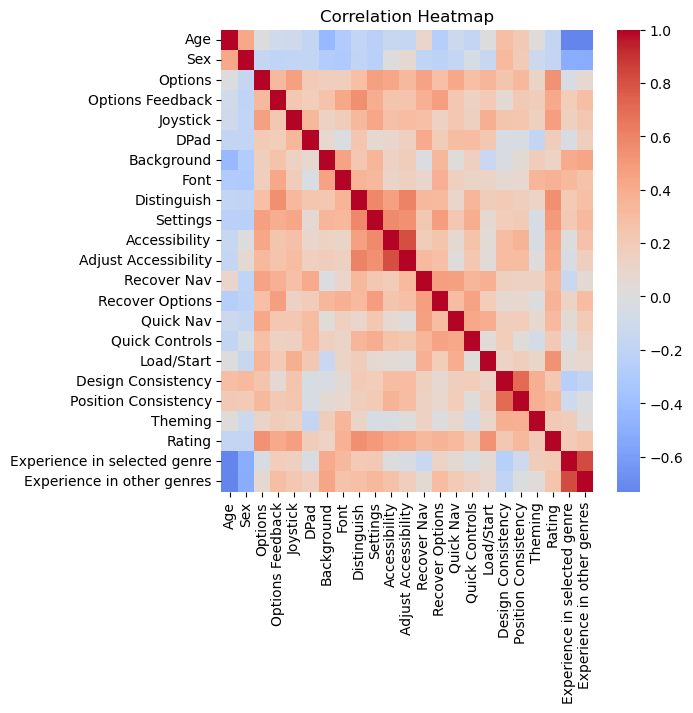

In [26]:
#plot heatmap of feature correlations
plt.figure(figsize=(6,6))
sns.heatmap(dataCorr, annot=False, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.show()

<Figure size 640x480 with 0 Axes>

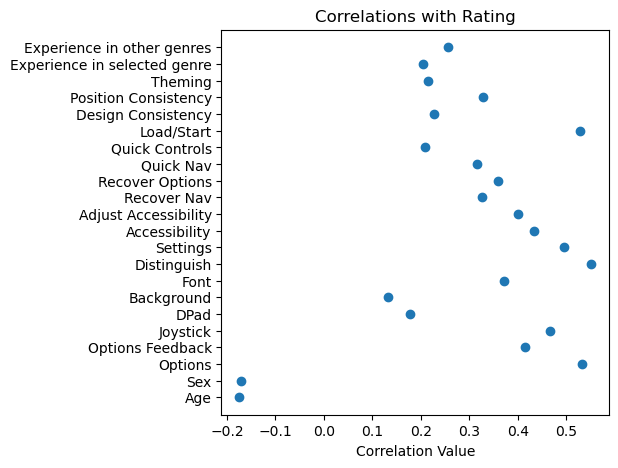

In [27]:
#plot data correlations against rating
plt.figure()
fig, ax = plt.subplots(figsize = (5,5))

plt.plot(dataCorr.drop('Rating')['Rating'], dataCorr.drop('Rating', axis=1).columns, 'o')
plt.xlabel("Correlation Value")
plt.title("Correlations with Rating")
plt.show()

<Figure size 640x480 with 0 Axes>

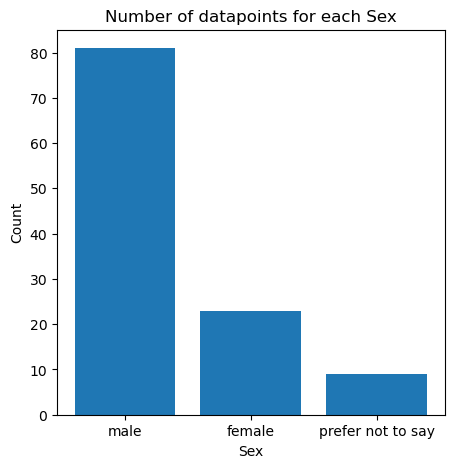

In [28]:
#plot sex against number of datapoints
plt.figure()
fig, ax = plt.subplots(figsize = (5,5))

plt.bar(['male','female','prefer not to say'], data_exploded['Sex'].value_counts())
plt.xlabel("Sex")
plt.ylabel("Count")
plt.title("Number of datapoints for each Sex")

plt.show()

In [29]:
#print number of datapoints for each sex
data_exploded['Sex'].value_counts()

Sex
0.0    81
1.0    23
0.5     9
Name: count, dtype: int64

<Figure size 640x480 with 0 Axes>

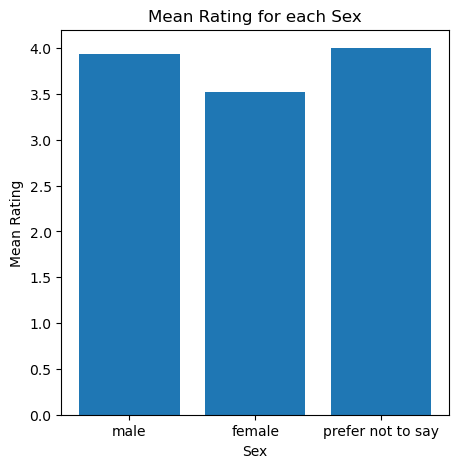

In [30]:
#plot sex against mean rating
plt.figure()
fig, ax = plt.subplots(figsize = (5,5))

plt.bar(['male','female','prefer not to say'], data_exploded.groupby('Sex', sort=False)['Rating'].mean())
plt.xlabel("Sex")
plt.ylabel("Mean Rating")
plt.title("Mean Rating for each Sex")

plt.show()

In [31]:
#print mean rating for each sex
data_exploded.groupby('Sex')['Rating'].mean()

Sex
0.0    3.938272
0.5    4.000000
1.0    3.521739
Name: Rating, dtype: float64

<Figure size 640x480 with 0 Axes>

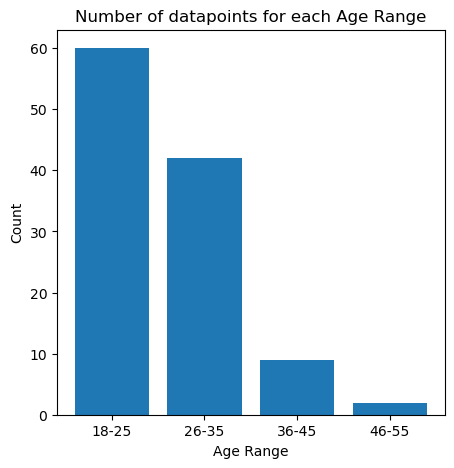

In [32]:
#plot age range against number of datapoints
plt.figure()
fig, ax = plt.subplots(figsize = (5,5))

plt.bar(['18-25','26-35','36-45','46-55'], data_exploded['Age'].value_counts())
plt.xlabel("Age Range")
plt.ylabel("Count")
plt.title("Number of datapoints for each Age Range")

plt.show()

In [33]:
#print number of datapoints for each age range
data_exploded['Age'].value_counts()

Age
21.5    60
50.5    42
40.5     9
30.5     2
Name: count, dtype: int64

<Figure size 640x480 with 0 Axes>

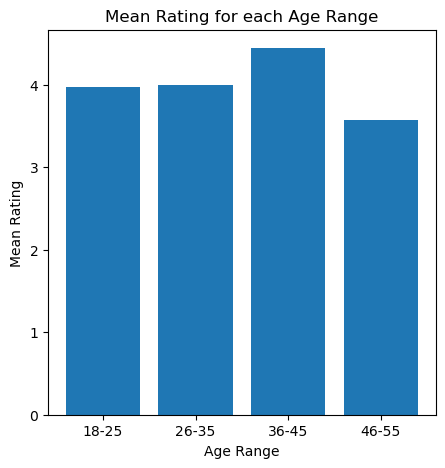

In [34]:
#plot age range against mean rating
plt.figure()
fig, ax = plt.subplots(figsize = (5,5))

plt.bar(['18-25','26-35','36-45','46-55'], data_exploded.groupby('Age')['Rating'].mean())
plt.xlabel("Age Range")
plt.ylabel("Mean Rating")
plt.title("Mean Rating for each Age Range")

plt.show()

In [35]:
#print mean rating for each age range
data_exploded.groupby('Age')['Rating'].mean()

Age
21.5    3.966667
30.5    4.000000
40.5    4.444444
50.5    3.571429
Name: Rating, dtype: float64

<Figure size 640x480 with 0 Axes>

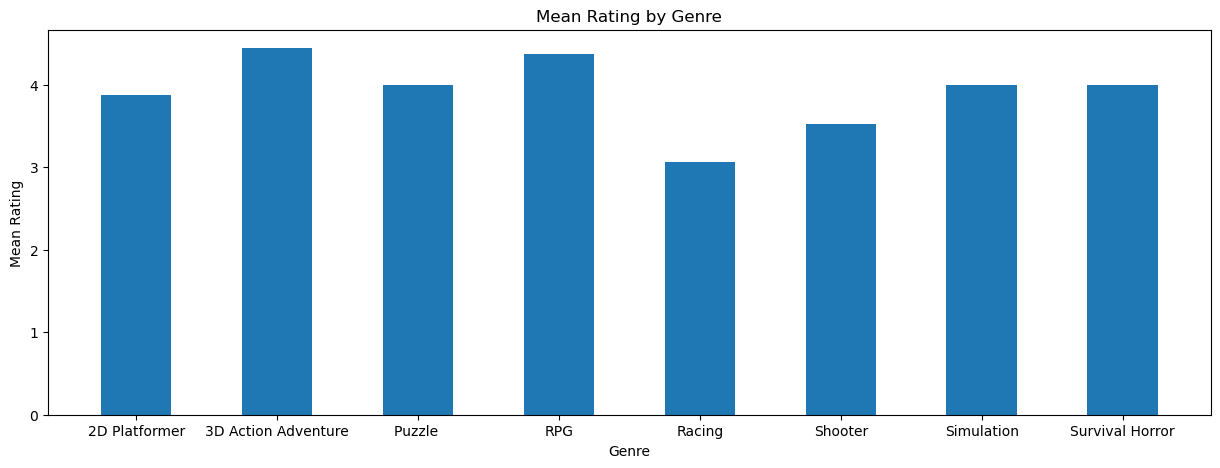

In [36]:
#plot genre against mean rating
plt.figure()
fig, ax = plt.subplots(figsize = (15,5))

plt.bar(data_exploded['Genre'].sort_values().unique(), data_exploded.groupby('Genre')['Rating'].mean().tolist(), 0.5)
plt.xlabel("Genre")
plt.ylabel("Mean Rating")
plt.title('Mean Rating by Genre')
plt.show()

In [37]:
#print mean rating for each genre
data_exploded.groupby('Genre')['Rating'].mean()

Genre
2D Platformer          3.875000
3D Action Adventure    4.444444
Puzzle                 4.000000
RPG                    4.368421
Racing                 3.066667
Shooter                3.526316
Simulation             4.000000
Survival Horror        4.000000
Name: Rating, dtype: float64

In [38]:
#calculate mean ratings per game
data_exploded.groupby('Favourite Game')['Rating'].mean().sort_values()

Favourite Game
Gran Turismo            1.800000
Rayman                  2.000000
Forza                   3.000000
Escape from tarkov      3.000000
Castlevania             3.000000
Helldivers 2            3.000000
Call of Duty            3.250000
Doom                    3.250000
Halo                    3.666667
Metroid                 3.750000
Titanfall               4.000000
Geometry Dash           4.000000
Honkai Star Rail        4.000000
Mario Kart              4.000000
Ori                     4.000000
Persona                 4.000000
Red Dead Redemption     4.000000
Resident Evil           4.000000
Silent Hill             4.000000
Kirby Air Riders        4.000000
Sonic Racing            4.000000
Donkey Kong Country     4.000000
Cuphead                 4.000000
Super Mario             4.000000
 FIFA                   4.000000
 Islands of Insight     4.000000
 Planet Coaster         4.000000
 The Witness            4.000000
Stardew Valley          4.000000
 dayz                   4.00

<Figure size 640x480 with 0 Axes>

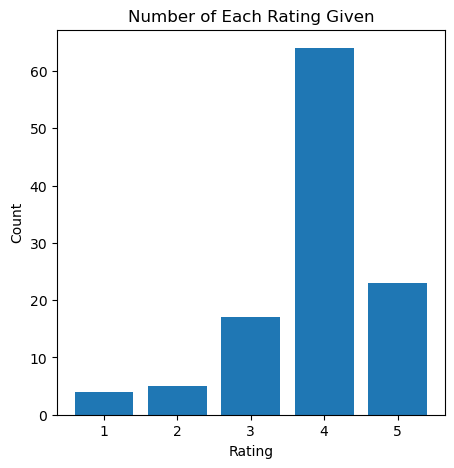

In [39]:
#plot rating against number of datapoints
plt.figure()
fig, ax = plt.subplots(figsize = (5,5))

plt.bar([1,2,3,4,5], data_exploded['Rating'].sort_values().value_counts(sort=False))
plt.xlabel("Rating")
plt.ylabel("Count")
plt.title("Number of Each Rating Given")

plt.show()

In [40]:
#print number of datapoints for each rating
data_exploded['Rating'].value_counts()

Rating
4    64
5    23
3    17
2     5
1     4
Name: count, dtype: int64

In [41]:
#split data into features usable for machine learning and the feature to predict
x1=data_exploded.drop(['Console','Genre','Favourite Game','Rating'], axis=1)
y=data_exploded['Rating']

#perform LASSO Feature Selection with cross validation to determine which features should be used for machine learning
lasso = LassoCV(cv=5, random_state=42)
lasso.fit(x1, y)

#show selected features
coef_df = pd.DataFrame({
    "feature": x1.columns,
    "coefficient": lasso.coef_
}).sort_values("coefficient", ascending=False)

coef_df

,feature,coefficient
16,Load/Start,0.264781
8,Distinguish,0.240782
2,Options,0.150853
9,Settings,0.099668
10,Accessibility,0.085405
7,Font,0.071872
18,Position Consistency,0.055785
19,Theming,0.040004
4,Joystick,0.024433
11,Adjust Accessibility,0.000000


<Figure size 640x480 with 0 Axes>

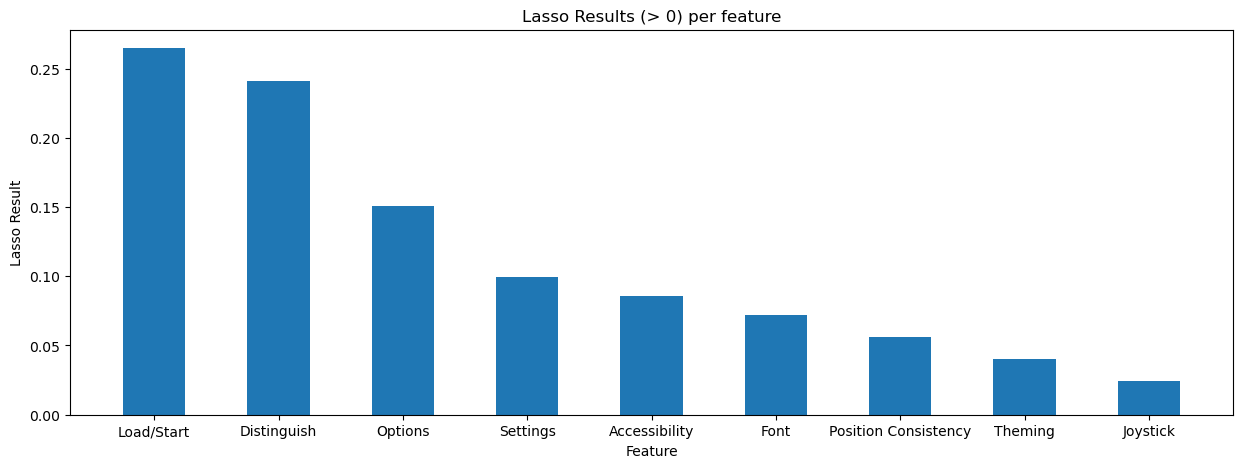

In [42]:
#plot lasso results aginst feature
plt.figure()
fig, ax = plt.subplots(figsize = (15,5))

plt.bar(coef_df['feature'].loc[coef_df['coefficient']>0], coef_df['coefficient'].loc[coef_df['coefficient']>0], 0.5)
plt.ylabel("Lasso Result")
plt.xlabel("Feature")
plt.title('Lasso Results (> 0) per feature')
plt.show()

<Figure size 640x480 with 0 Axes>

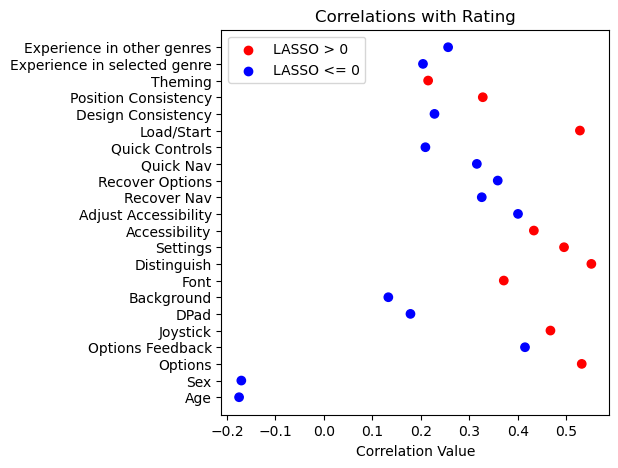

In [43]:
#plot data correlations against rating coloured by lasso result
plt.figure()
fig, ax = plt.subplots(figsize = (5,5))

colour = []
for col in dataCorr.drop('Rating', axis=1).columns:
    if coef_df['feature'].loc[coef_df['coefficient']>0].str.contains(col).sum()>0:
        c = "r"
    else:
        c = "b"
    colour.append(c)

red_handle = plt.scatter([], [], color="r", label="LASSO > 0")
blue_handle = plt.scatter([], [], color="b", label="LASSO <= 0")

plt.legend(handles=[red_handle, blue_handle], loc="upper left")
plt.xlabel("Correlation Value")

plt.scatter(dataCorr.drop('Rating')['Rating'], dataCorr.drop('Rating', axis=1).columns, color=colour)
plt.title("Correlations with Rating")
plt.show()

In [44]:
#remove features with little impact on rating
x=data_exploded.drop(['Console','Genre','Favourite Game','Rating','Adjust Accessibility' , 'Quick Nav', 'Experience in selected genre', 'Design Consistency', 'Quick Controls', 'Experience in other genres', 'Recover Options', 'Recover Nav', 'Sex', 'Background', 'DPad', 'Options Feedback', 'Age'], axis=1)

#split data into train and test data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [45]:
#train linear regression model
LiR_model = LinearRegression()

LiR_model.fit(x_train, y_train)

LinearRegression()

In [46]:
#obtain R-squared score for linear regression model
LiR_y_score=LiR_model.score(x, y)
LiR_y_score

0.6187669733512482

In [47]:
#obtain predictions for linear regression model
LiR_y_pred = LiR_model.predict(x_test)

#calculate root mean square error and absolute error for linear regression
LiR_rmse = np.sqrt(metrics.mean_squared_error(y_test, LiR_y_pred))
LiR_mae = metrics.mean_absolute_error(y_test, LiR_y_pred)
print("RMSE:", LiR_rmse, "\nMAE:", LiR_mae)

RMSE: 0.5821202627071965 
MAE: 0.45517789990849306


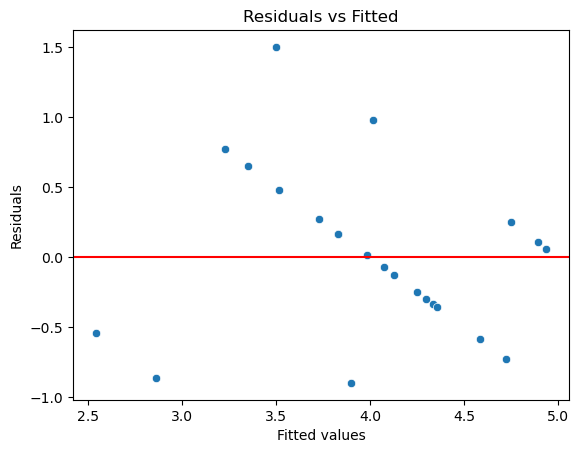

In [48]:
#calculate and plot residuals against fitted values for linear regression model
LiR_residuals = y_test - LiR_y_pred

sns.scatterplot(x=LiR_y_pred, y=LiR_residuals)
plt.axhline(0, color='red')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

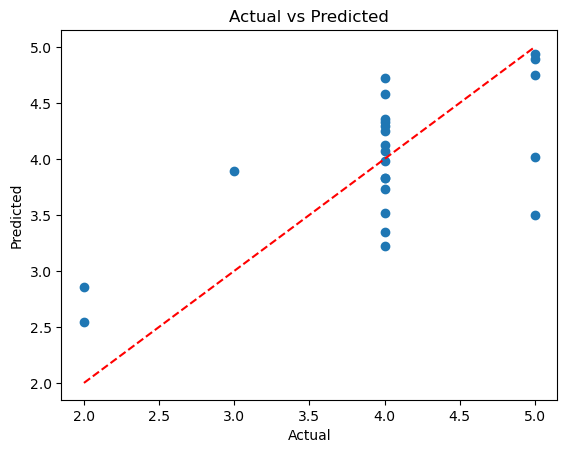

In [49]:
#plot actual values against predicted values for linear regression model
plt.scatter(y_test, LiR_y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

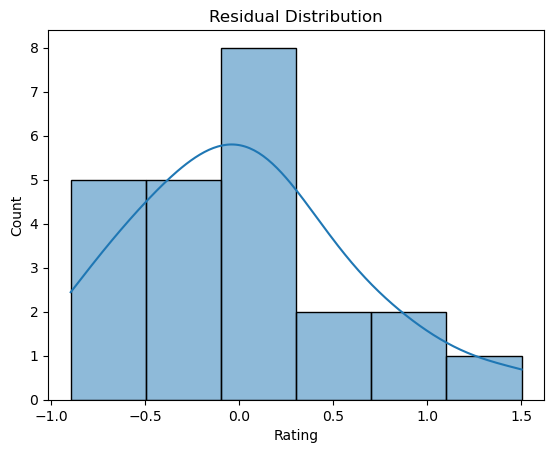

In [50]:
#plot residual distribution for linear regression model
sns.histplot(LiR_residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

In [51]:
#train logistic regression model
LoR_model = LogisticRegression(random_state=42, max_iter=143)

LoR_model.fit(x_train, y_train)

LogisticRegression(max_iter=143, random_state=42)

In [52]:
#obtain R-squared score for logistic regression model
LoR_y_score = LoR_model.score(x, y)
LoR_y_score

0.8141592920353983

In [53]:
#obtain predictions for logistic regression model
LoR_y_pred = LoR_model.predict(x_test)

#calculate root mean square error and absolute error for logistic regression
LoR_rmse = np.sqrt(metrics.mean_squared_error(y_test, LoR_y_pred))
LoR_mae = metrics.mean_absolute_error(y_test, LoR_y_pred)
print("RMSE:", LoR_rmse, "\nMAE:", LoR_mae)

RMSE: 0.6915640748081247 
MAE: 0.391304347826087


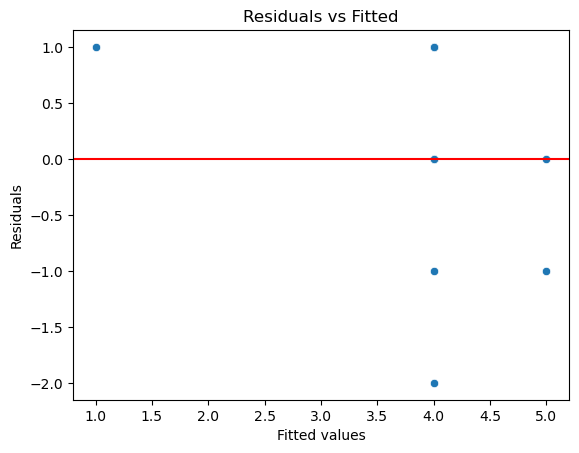

In [54]:
#calculate and plot residuals against fitted values for logistic regression model
LoR_residuals = y_test - LoR_y_pred

sns.scatterplot(x=LoR_y_pred, y=LoR_residuals)
plt.axhline(0, color='red')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

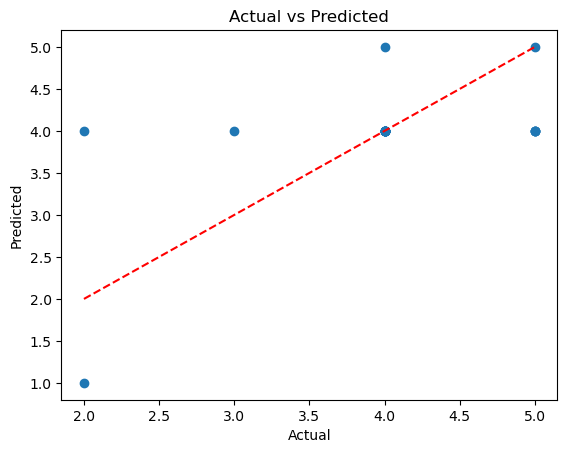

In [55]:
#plot actual values against predicted values for logistic regression model
plt.scatter(y_test, LoR_y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

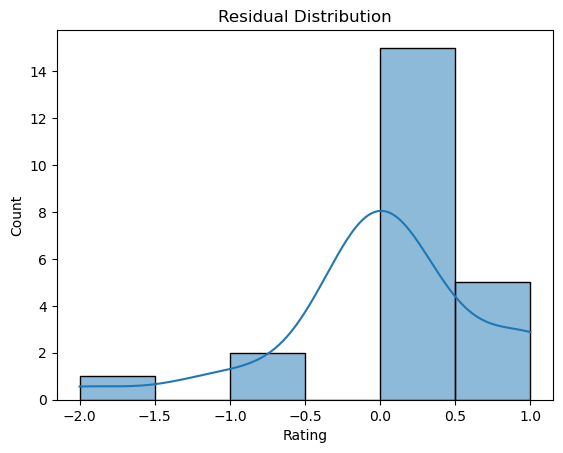

In [56]:
#plot residual distribution for logistic regression model
sns.histplot(LoR_residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

In [57]:
#train support vector regression model
#c is regularisation parameter (inversly peoportional)
SVR_model = SVR(kernel='rbf', C=1, gamma=0.5, epsilon=0.1)

SVR_model.fit(x_train, y_train)

SVR(C=1, gamma=0.5)

In [58]:
#obtain R-squared score for support vector regression model
SVR_y_score = SVR_model.score(x, y)
SVR_y_score

0.7534531859866846

In [59]:
#obtain predictions for support vector regression model
SVR_y_pred = SVR_model.predict(x_test)

#calculate root mean square error and absolute error for support vector regression
SVR_rmse = np.sqrt(metrics.mean_squared_error(y_test, SVR_y_pred))
SVR_mae = metrics.mean_absolute_error(y_test, SVR_y_pred)
print("RMSE:", SVR_rmse, "\nMAE:", SVR_mae)

RMSE: 0.6730844400879243 
MAE: 0.43035687974616044


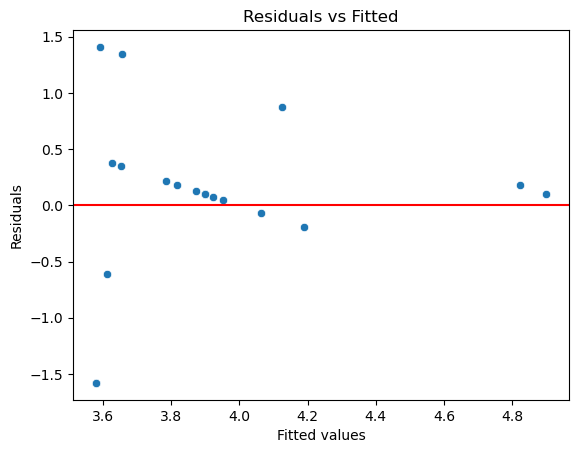

In [60]:
#calculate and plot residuals against fitted values for support vector regression model
SVR_residuals = y_test - SVR_y_pred

sns.scatterplot(x=SVR_y_pred, y=SVR_residuals)
plt.axhline(0, color='red')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

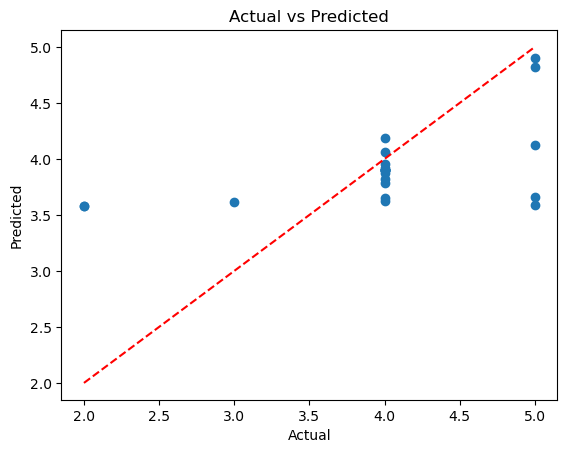

In [61]:
#plot actual values against predicted values for support vector regression model
plt.scatter(y_test, SVR_y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

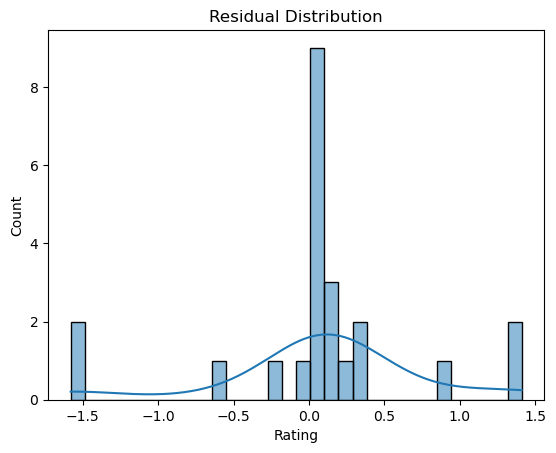

In [62]:
#plot residual distribution for support vector regression model
sns.histplot(SVR_residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

In [63]:
#train random forest regression model
RF_model = RandomForestRegressor(n_estimators=500, max_depth=None, random_state=42)

RF_model.fit(x_train, y_train)

RandomForestRegressor(n_estimators=500, random_state=42)

In [64]:
#obtain R-squared score for random forest regression model
RF_y_score = RF_model.score(x, y)
RF_y_score

0.9097520891238671

In [65]:
#obtain predictions for random forest regression model
RF_y_pred = RF_model.predict(x_test)

#calculate root mean square error and absolute error for random forest regression
RF_rmse = np.sqrt(metrics.mean_squared_error(y_test, RF_y_pred))
RF_mae = metrics.mean_absolute_error(y_test, RF_y_pred)
print("RMSE:", RF_rmse, "\nMAE:", RF_mae)

RMSE: 0.4444351569077901 
MAE: 0.266695652173913


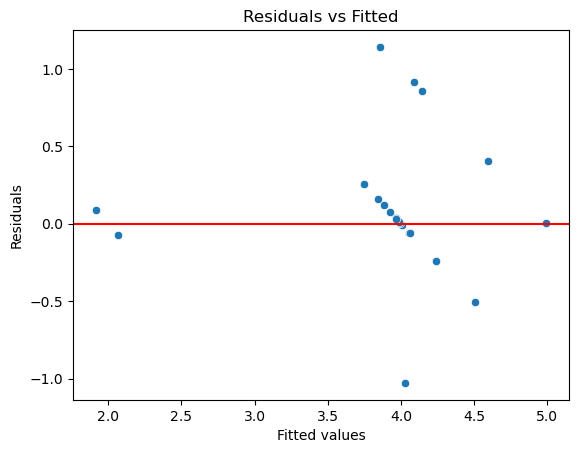

In [66]:
#calculate and plot residuals against fitted values for random forest regression model
RF_residuals = y_test - RF_y_pred

sns.scatterplot(x=RF_y_pred, y=RF_residuals)
plt.axhline(0, color='red')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

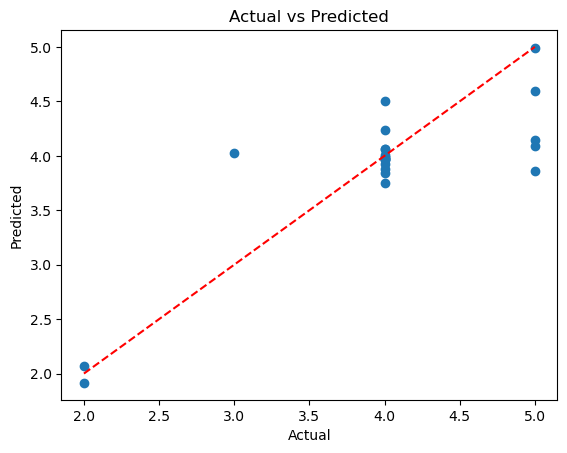

In [67]:
#plot actual values against predicted values for random forest regression model
plt.scatter(y_test, RF_y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

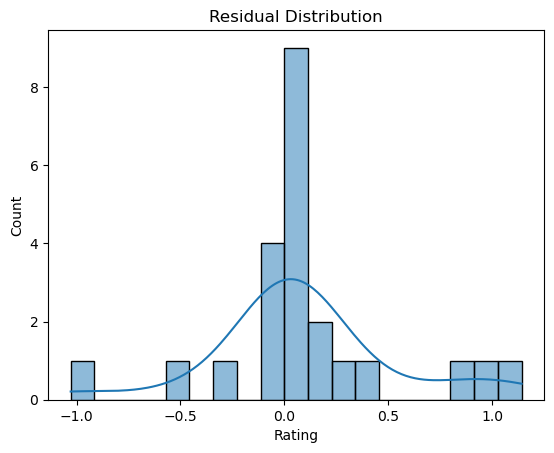

In [68]:
#plot residual distribution for random forest regression model
sns.histplot(RF_residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

In [69]:
#train xgb regression model
XGB_model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=42)

XGB_model.fit(x_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [70]:
#obtain R-squared score for xgb regression model
XGB_y_score = XGB_model.score(x, y)
XGB_y_score

0.9300846274424855

In [71]:
#obtain predictions for xgb regression model
XGB_y_pred = XGB_model.predict(x_test)

#calculate root mean square error and absolute error for xgb regression
XGB_rmse = np.sqrt(metrics.mean_squared_error(y_test, XGB_y_pred))
XGB_mae = metrics.mean_absolute_error(y_test, XGB_y_pred)
print("RMSE:", XGB_rmse, "\nMAE:", XGB_mae)

RMSE: 0.533679506154087 
MAE: 0.33378468389096466


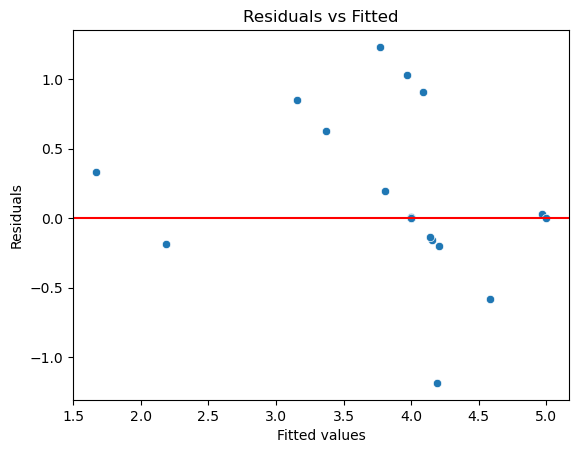

In [72]:
#calculate and plot residuals against fitted values for xgb regression model
XGB_residuals = y_test - XGB_y_pred

sns.scatterplot(x=XGB_y_pred, y=XGB_residuals)
plt.axhline(0, color='red')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

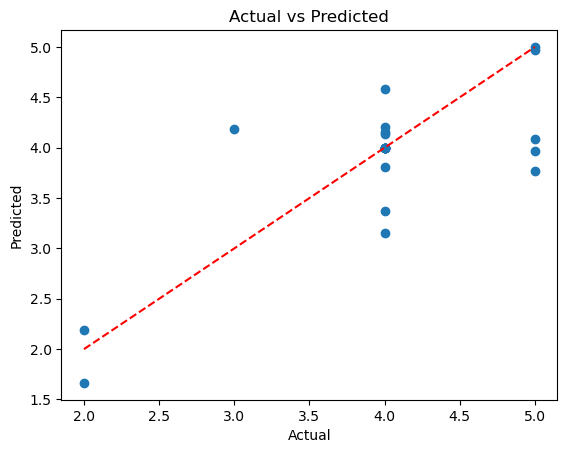

In [73]:
#plot actual values against predicted values for xgb regression model
plt.scatter(y_test, XGB_y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

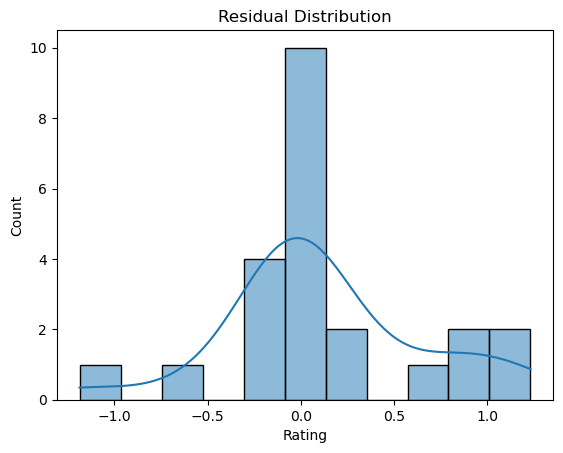

In [74]:
#plot residual distribution for xgb regression model
sns.histplot(XGB_residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

In [75]:
#gather features for cat boost regression
cat_cols = x.select_dtypes(include="object").columns.tolist()

train_pool = Pool(x_train, y_train, cat_features=cat_cols)
test_pool = Pool(x_test, y_test, cat_features=cat_cols)

#train cat boost regression model
CBR_model = CatBoostRegressor(iterations=800, learning_rate=0.05, depth=6, loss_function="RMSE", random_seed=42, verbose=False)

CBR_model.fit(train_pool)

In [76]:
#obtain R-squared score for catboost regression model
CBR_y_score = CBR_model.score(x, y)
CBR_y_score

0.9391305238690238

In [77]:
#obtain predictions for catboost regression model
CBR_y_pred = CBR_model.predict(x_test)

#calculate root mean square error and absolute error for cat boost regression
CBR_rmse = np.sqrt(metrics.mean_squared_error(y_test, CBR_y_pred))
CBR_mae = metrics.mean_absolute_error(y_test, CBR_y_pred)
print("RMSE:", CBR_rmse, "\nMAE:", CBR_mae)

RMSE: 0.49681625661883794 
MAE: 0.31154613618016785


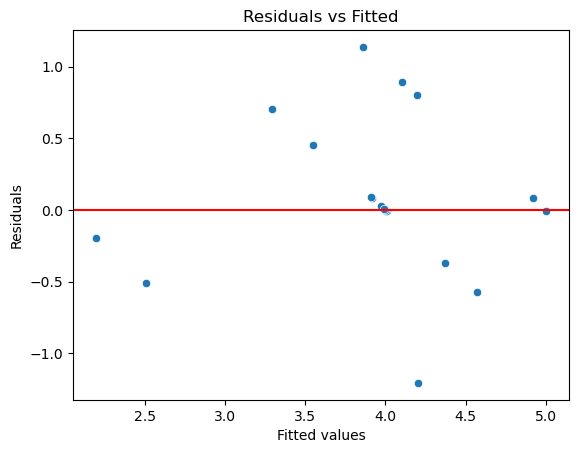

In [78]:
#calculate and plot residuals against fitted values for catboost regression model
CBR_residuals = y_test - CBR_y_pred

sns.scatterplot(x=CBR_y_pred, y=CBR_residuals)
plt.axhline(0, color='red')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

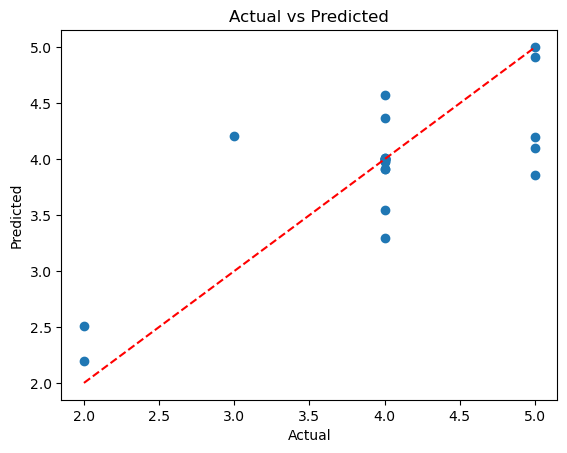

In [79]:
#plot actual values against predicted values for catboost regression model
plt.scatter(y_test, CBR_y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

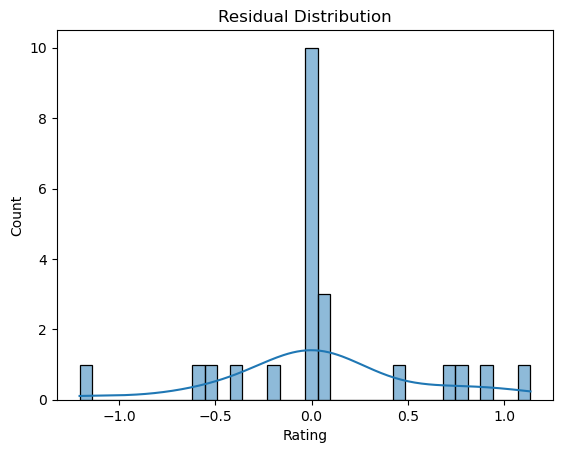

In [80]:
#plot residual distribution for catboost regression model
sns.histplot(CBR_residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

In [81]:
#compare metrics from models
df = pd.DataFrame(data={
    "R-Squared": [LiR_y_score, LoR_y_score, SVR_y_score, RF_y_score, XGB_y_score, CBR_y_score], 
    "RMSE": [LiR_rmse, LoR_rmse, SVR_rmse, RF_rmse, XGB_rmse, CBR_rmse],
    "MAE": [LiR_mae, LoR_mae, SVR_mae, RF_mae, XGB_mae, CBR_mae],
    }, index=["Linear Regression", "Logistic Regression", "Support Vector Regression", "Random Forest Regression", "XGBoost Regression", "Cat Boost Regression"])
df

,R-Squared,RMSE,MAE
Linear Regression,0.618767,0.582120,0.455178
Logistic Regression,0.814159,0.691564,0.391304
Support Vector Regression,0.753453,0.673084,0.430357
Random Forest Regression,0.909752,0.444435,0.266696
XGBoost Regression,0.930085,0.533680,0.333785
Cat Boost Regression,0.939131,0.496816,0.311546


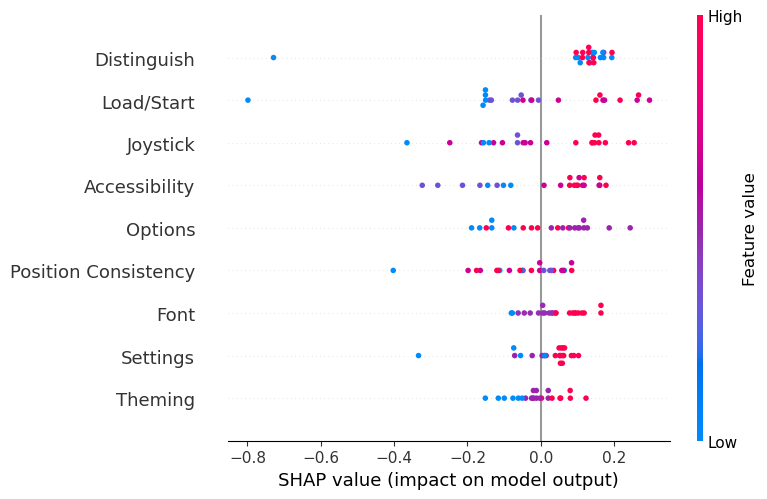

In [82]:
#create shap explainer for cat boost model
CBR_explainer = shap.TreeExplainer(CBR_model)
CBR_shap_values = CBR_explainer.shap_values(x_test)

#create shap summary plot to help determine which features are most important to the model
shap.summary_plot(CBR_shap_values, x_test)

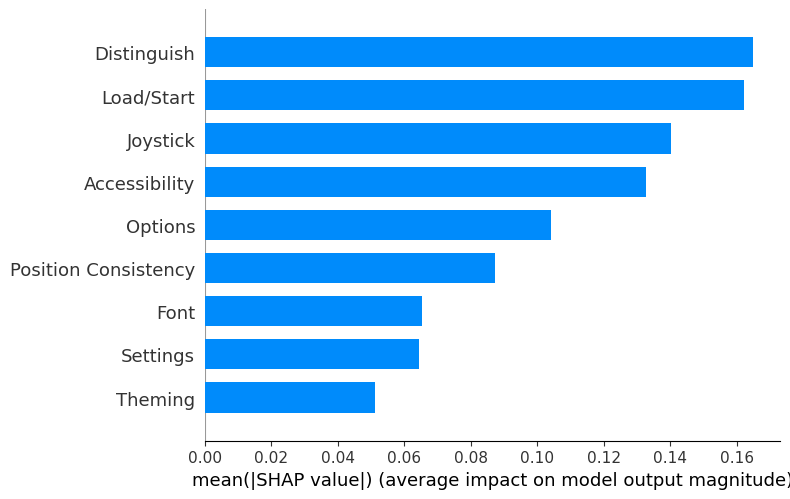

In [83]:
#create a shap bar plot to visualise a clear ranking of the feature importance
shap.summary_plot(CBR_shap_values, x_test, plot_type="bar")

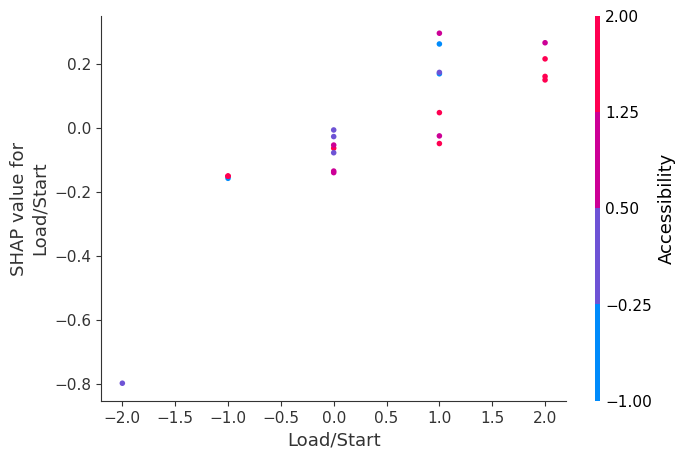

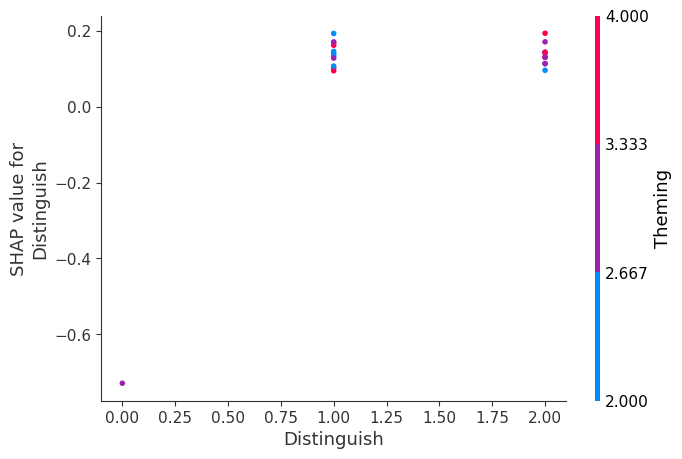

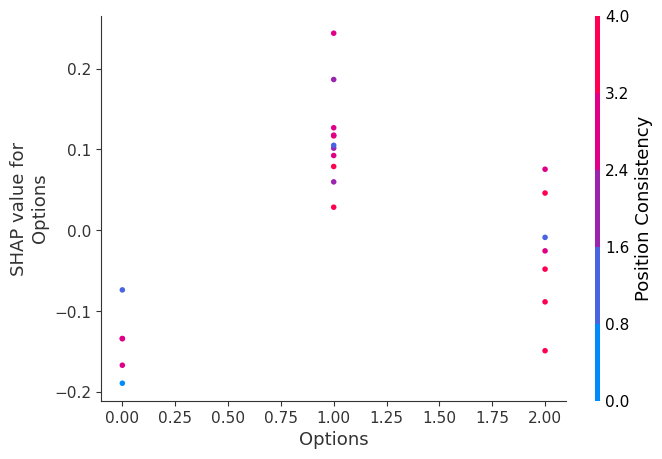

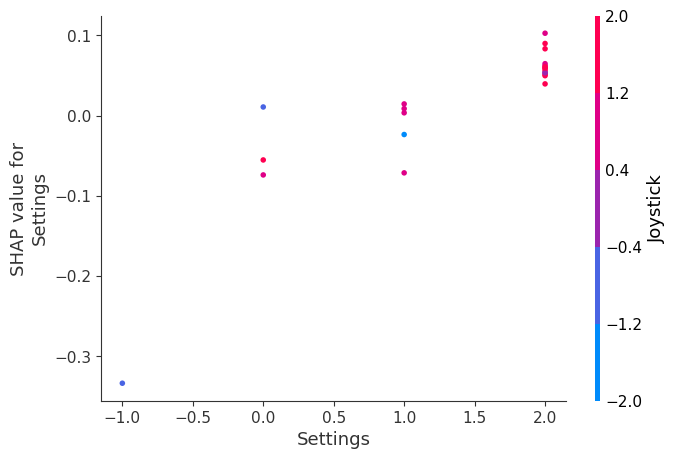

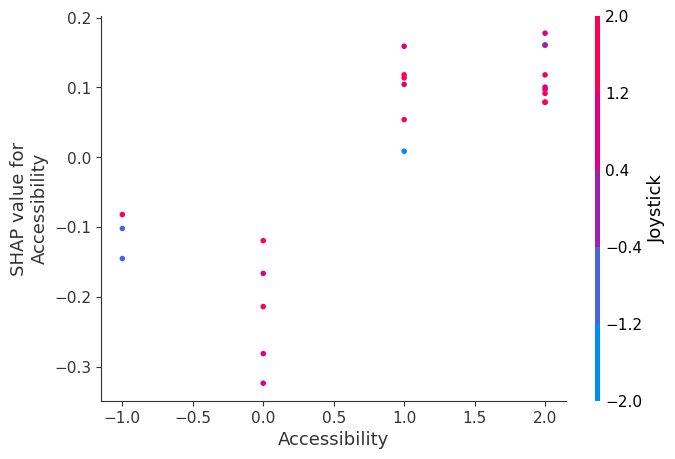

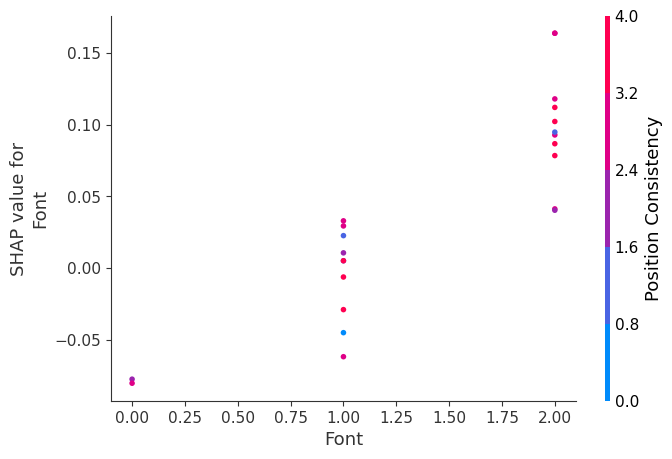

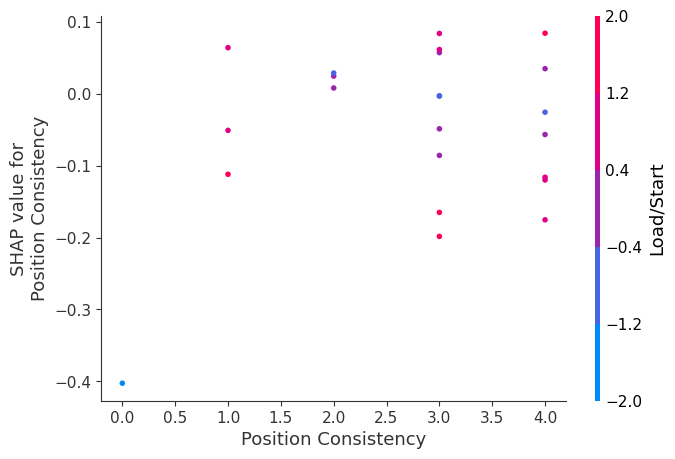

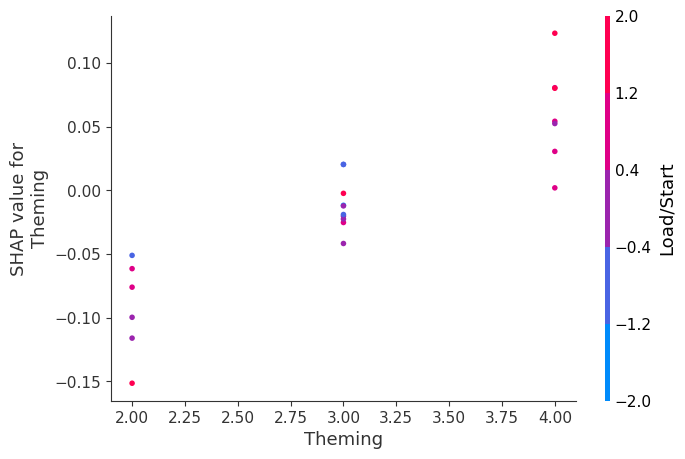

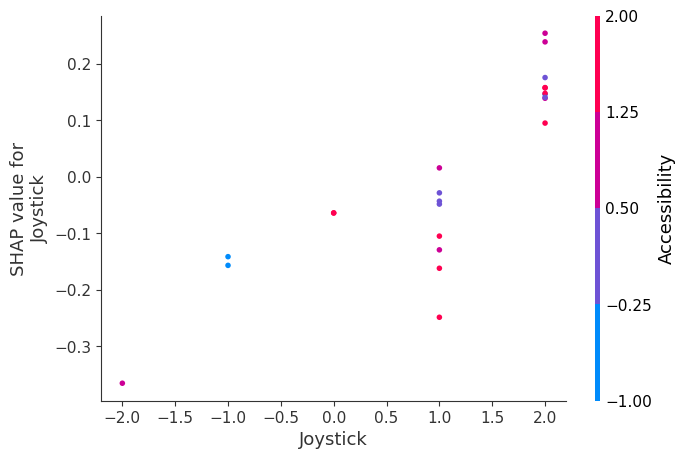

In [84]:
#create shap dependence plots for each feature to show feature interactions
for feat in coef_df['feature']:
    if feat in x_test.columns:
        shap.dependence_plot(feat, CBR_shap_values, x_test)

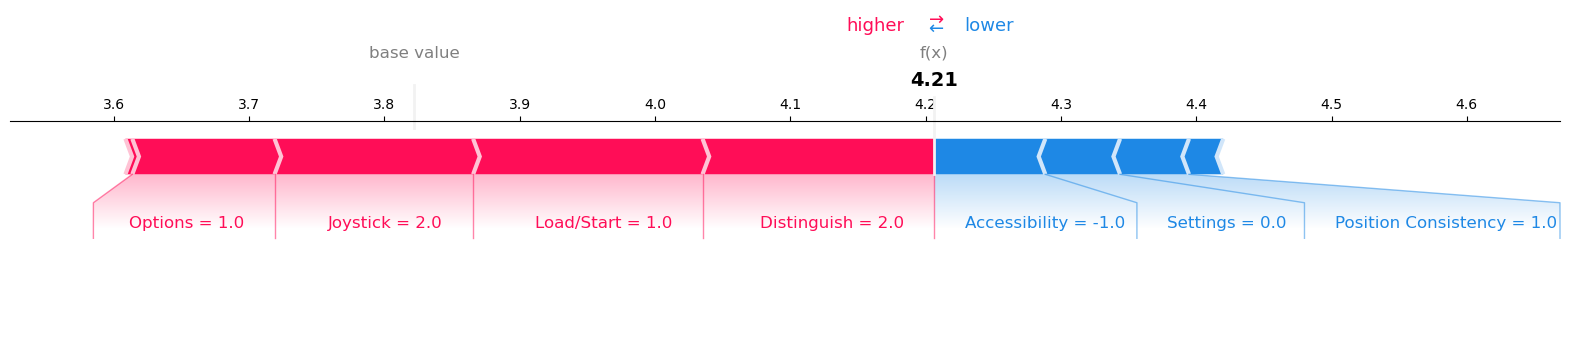

In [85]:
i = 0  #index of the participant you want to explain

#create a shap force plot to show the reasoning behind a single prediction
shap.force_plot(CBR_explainer.expected_value, CBR_shap_values[i], x_test.iloc[i], matplotlib=True)

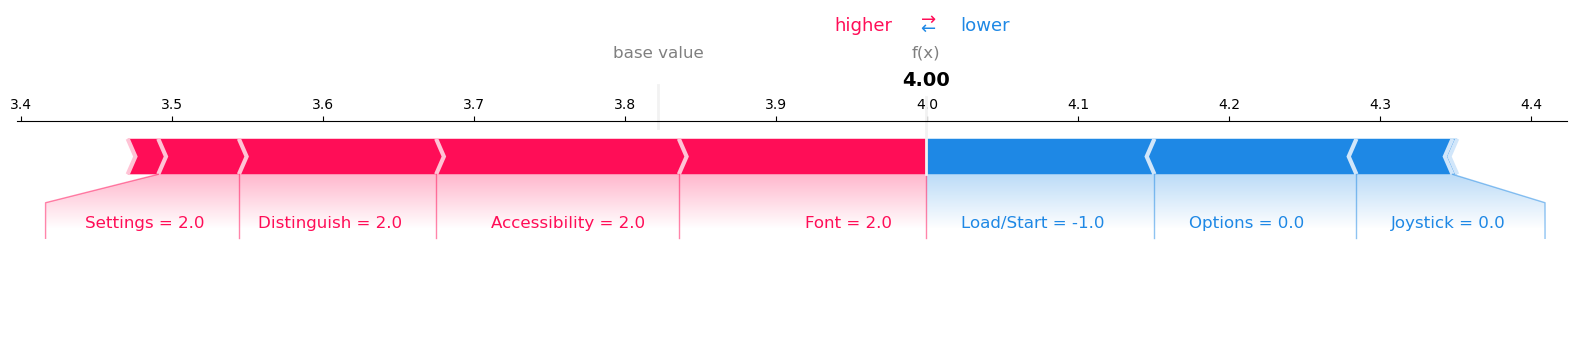

In [86]:
i = 5  #index of the participant you want to explain

#create a shap force plot to show the reasoning behind a single prediction
shap.force_plot(CBR_explainer.expected_value, CBR_shap_values[i], x_test.iloc[i], matplotlib=True)

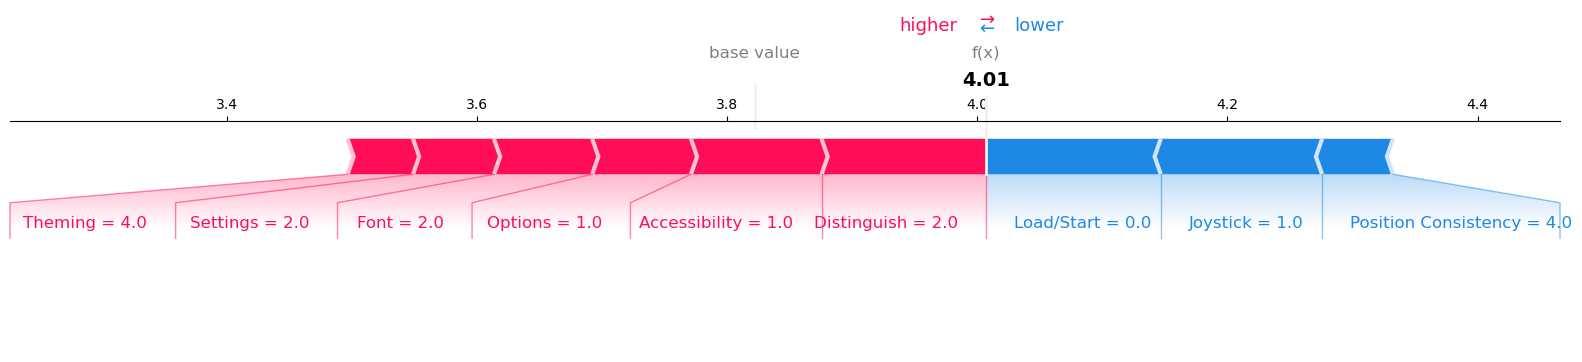

In [87]:
i = 11  #index of the participant you want to explain

#create a shap force plot to show the reasoning behind a single prediction
shap.force_plot(CBR_explainer.expected_value, CBR_shap_values[i], x_test.iloc[i], matplotlib=True)

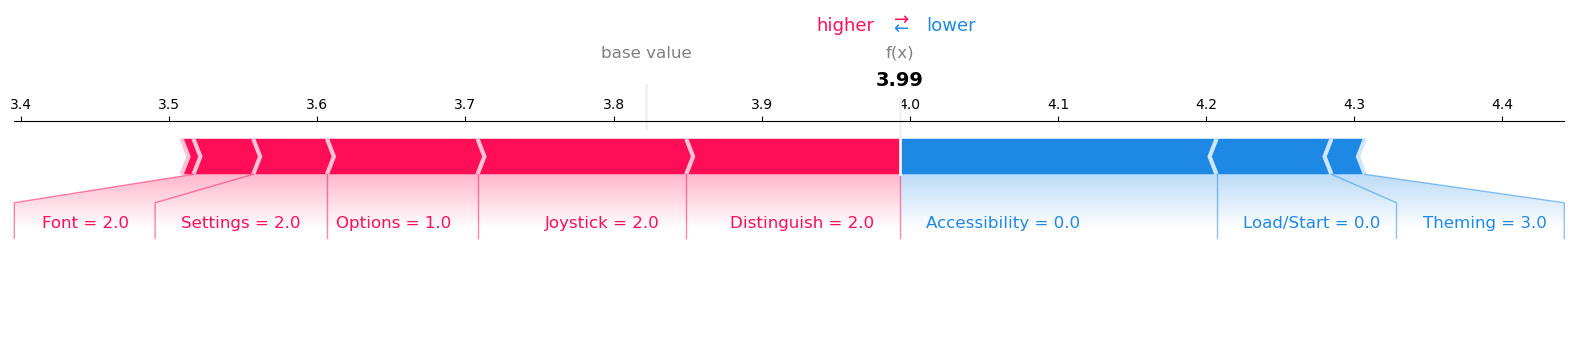

In [88]:
i = 22  #index of the participant you want to explain

#create a shap force plot to show the reasoning behind a single prediction
shap.force_plot(CBR_explainer.expected_value, CBR_shap_values[i], x_test.iloc[i], matplotlib=True)

In [89]:
#print base value for predictions
print(CBR_explainer.expected_value)

3.8221552255986375
